# Results analysis: do the agents beat buy-and-hold?

Build step 7. Every number here is read from PostgreSQL with the **read-only** role, from the same
views the assistant and dashboard use (`strategy_results`, `strategy_baseline_comparisons`,
`buy_and_hold_baselines`). Re-run with `make analysis` after `make train` or `make refresh`.

A **strategy** is one ticker + algorithm + feature set, trained with several seeds. Its seeds are
averaged as an equal-weight portfolio. **Excess return** = (1 + strategy return) / (1 + buy-and-hold
return) − 1. A strategy **beats buy-and-hold** only if the whole confidence interval of its excess
return (moving-block bootstrap over trading days) is above zero.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # run from notebooks/

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.database import connect_as_reader
from src.settings import load_settings

settings = load_settings()

def read(sql):
    with connect_as_reader() as conn:
        return pd.DataFrame(conn.execute(sql).fetchall())

results = read("SELECT * FROM strategy_results")
comparisons = read("SELECT * FROM strategy_baseline_comparisons")
baselines = read("SELECT * FROM buy_and_hold_baselines")
seed_metrics = read('''SELECT r.ticker, r.algorithm, r.feature_set, r.seed, m.*
                       FROM current_training_runs r JOIN run_metrics m ON m.run_id = r.id''')
w, t = settings.windows, settings.trading
print(f"Train {w.train_start} to {w.train_end}; test {w.test_start} to {w.test_end}; "
      f"fees {t.buy_fee_rate:.2%} buy / {t.sell_fee_rate:.2%} sell; "
      f"{settings.training.timesteps:,} timesteps; seeds {list(settings.training.seeds)}")
test_agents = (seed_metrics.evaluation_period == "test").sum()
print(f"{test_agents} trained agents with test results")

Train 2021-01-01 to 2024-12-31; test 2025-01-01 to 2025-12-31; fees 0.10% buy / 0.10% sell; 20,000 timesteps; seeds [0, 1, 2, 3, 4]
90 trained agents with test results


In [2]:
# Chart styling: reference palette, light surface, one colour per algorithm (fixed order),
# filled marker = indicators, hollow = standard. Every chart has a table with the same numbers.
ALGORITHM_COLORS = {"A2C": "#2a78d6", "DQN": "#eb6834", "PPO": "#1baf7a"}
INK, SECONDARY_INK, MUTED_INK, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": SECONDARY_INK, "xtick.color": MUTED_INK, "ytick.color": MUTED_INK,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
})
TICKERS = list(settings.market_data.tickers)

def pct(frame, columns):
    return frame.assign(**{c: (100 * frame[c]).round(2) for c in columns})

## 1. Buy-and-hold on the test window

One round trip per ticker, paying the same fees as the agents.

In [3]:
display(pct(baselines, ["total_return", "max_drawdown"])
        [["ticker", "evaluation_period", "period_start", "period_end", "trading_days", "total_return", "sharpe_ratio", "max_drawdown"]]
        .rename(columns={"total_return": "total_return_%", "max_drawdown": "max_drawdown_%"})
        .sort_values(["evaluation_period", "ticker"]).round(2))

,ticker,evaluation_period,period_start,period_end,trading_days,total_return_%,sharpe_ratio,max_drawdown_%
3,AMD,forward,2026-01-02,2026-11-04,212,118.29,1.66,28.11
4,INTC,forward,2026-01-02,2026-11-04,212,47.67,0.97,58.70
5,NVDA,forward,2026-01-02,2026-11-04,212,6.01,0.37,19.30
1,AMD,test,2025-01-02,2025-12-31,250,77.18,1.24,39.63
2,INTC,test,2025-01-02,2025-12-31,250,82.13,1.26,33.81
0,NVDA,test,2025-01-02,2025-12-31,250,34.61,0.85,36.88


## 2. Every strategy against buy-and-hold (test period)

In [4]:
test = (results.query("evaluation_period == 'test'")
        .merge(comparisons, on=["ticker", "algorithm", "feature_set", "evaluation_period"], suffixes=("", "_cmp")))
table = pct(test, ["mean_total_return", "stddev_total_return", "buy_and_hold_return", "excess_return",
                   "excess_return_ci_low", "excess_return_ci_high", "mean_max_drawdown", "mean_exposure"])
display(table[["ticker", "algorithm", "feature_set", "mean_total_return", "stddev_total_return", "buy_and_hold_return",
               "excess_return", "excess_return_ci_low", "excess_return_ci_high", "seeds_beating_buy_and_hold",
               "beats_buy_and_hold", "mean_sharpe_ratio", "mean_max_drawdown", "mean_trade_count", "mean_exposure"]]
        .sort_values(["ticker", "excess_return"], ascending=[True, False]).round(2).reset_index(drop=True))

,ticker,algorithm,feature_set,mean_total_return,stddev_total_return,buy_and_hold_return,excess_return,excess_return_ci_low,excess_return_ci_high,seeds_beating_buy_and_hold,beats_buy_and_hold,mean_sharpe_ratio,mean_max_drawdown,mean_trade_count,mean_exposure
0,AMD,A2C,indicators,55.44,30.25,77.18,-12.27,-36.20,24.30,1,False,1.09,33.44,6.4000000000000000,70.92
1,AMD,PPO,indicators,55.37,35.47,77.18,-12.31,-41.58,30.00,1,False,1.39,24.87,5.6000000000000000,62.09
2,AMD,PPO,standard,42.65,30.06,77.18,-19.49,-37.55,7.88,0,False,1.00,29.70,6.8000000000000000,67.15
3,AMD,DQN,standard,41.02,23.80,77.18,-20.41,-40.46,3.49,0,False,0.86,37.07,30.0000000000000000,80.32
4,AMD,DQN,indicators,33.24,13.84,77.18,-24.80,-56.16,20.76,0,False,0.96,28.47,52.0000000000000000,51.89
5,AMD,A2C,standard,32.26,44.75,77.18,-25.35,-58.93,35.43,1,False,1.29,14.30,0.80000000000000000000,38.15
6,INTC,PPO,indicators,73.09,71.28,82.13,-4.96,-59.40,113.47,2,False,1.69,9.78,9.6000000000000000,21.04
7,INTC,A2C,indicators,72.17,75.29,82.13,-5.47,-50.56,71.70,2,False,1.10,22.85,13.2000000000000000,49.88
8,INTC,DQN,indicators,71.99,40.01,82.13,-5.57,-44.26,58.05,3,False,1.38,22.44,45.6000000000000000,48.27
9,INTC,DQN,standard,31.44,32.99,82.13,-27.83,-60.08,27.17,0,False,0.81,24.93,28.8000000000000000,61.45


### Excess return with its confidence interval

Each dot is a strategy's seed-averaged excess return over buy-and-hold; the bar is its
confidence interval. Right of zero is better than buy-and-hold.

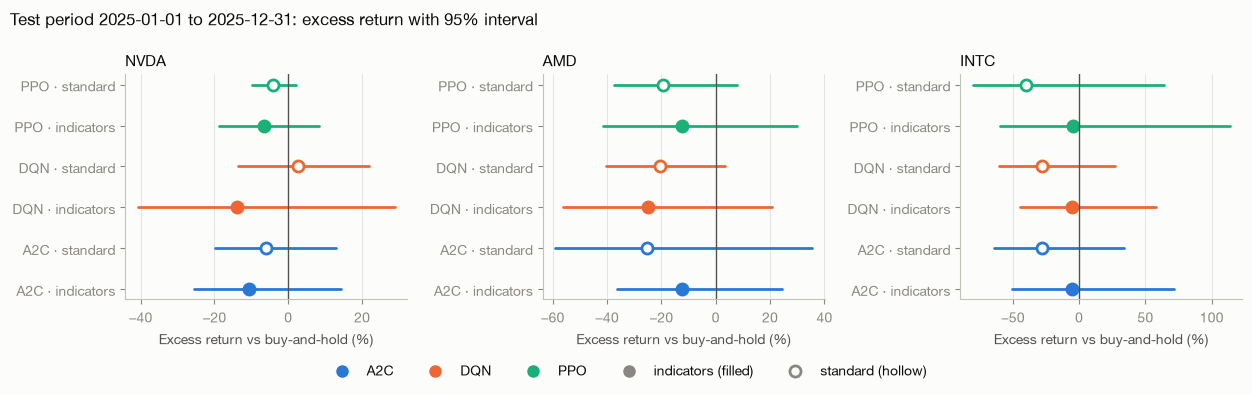

In [5]:
fig, axes = plt.subplots(1, len(TICKERS), figsize=(4.2 * len(TICKERS), 3.6), sharex=False)
for ax, ticker in zip(axes, TICKERS):
    rows = test[test.ticker == ticker].sort_values(["algorithm", "feature_set"]).reset_index(drop=True)
    for y, row in rows.iterrows():
        color = ALGORITHM_COLORS[row.algorithm]
        filled = row.feature_set == "indicators"
        ax.plot([100 * row.excess_return_ci_low, 100 * row.excess_return_ci_high], [y, y], color=color, lw=2,
                solid_capstyle="round")
        ax.plot(100 * row.excess_return, y, "o", ms=8, color=color, mfc=color if filled else SURFACE, mew=2)
    ax.axvline(0, color=SECONDARY_INK, lw=1)
    ax.set_yticks(range(len(rows)), [f"{a} · {f}" for a, f in zip(rows.algorithm, rows.feature_set)])
    ax.set_title(ticker, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("Excess return vs buy-and-hold (%)")
    ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, ms=8, label=a) for a, c in ALGORITHM_COLORS.items()]
handles += [plt.Line2D([], [], marker="o", ls="", color=MUTED_INK, ms=8, label="indicators (filled)"),
            plt.Line2D([], [], marker="o", ls="", color=MUTED_INK, mfc=SURFACE, mew=2, ms=8, label="standard (hollow)")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Test period {w.test_start} to {w.test_end}: excess return with {settings.analysis.confidence_level:.0%} interval",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()

### Spread across seeds

Each dot is one seed's test return; the grey line is buy-and-hold. A strategy whose seeds
scatter widely around buy-and-hold has no dependable edge, whatever its mean.

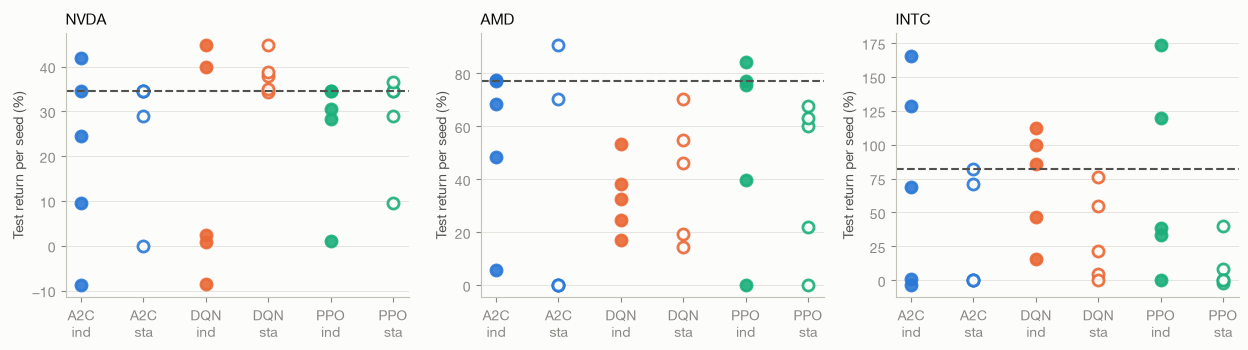

In [6]:
fig, axes = plt.subplots(1, len(TICKERS), figsize=(4.2 * len(TICKERS), 3.6))
seed_test = seed_metrics[seed_metrics.evaluation_period == "test"]
for ax, ticker in zip(axes, TICKERS):
    labels = []
    for x, ((algorithm, feature_set), seeds) in enumerate(seed_test[seed_test.ticker == ticker]
                                                          .groupby(["algorithm", "feature_set"])):
        color = ALGORITHM_COLORS[algorithm]
        filled = feature_set == "indicators"
        ax.plot([x] * len(seeds), 100 * seeds.total_return, "o", ms=8, color=color, alpha=0.9,
                mfc=color if filled else SURFACE, mew=2)
        labels.append(f"{algorithm}\n{feature_set[:3]}")
    baseline = baselines.query("ticker == @ticker and evaluation_period == 'test'").total_return.iloc[0]
    ax.axhline(100 * baseline, color=SECONDARY_INK, lw=1.5, ls="--")
    ax.annotate(f"buy-and-hold {100 * baseline:.1f}%", (len(labels) - 0.5, 100 * baseline), ha="right",
                va="bottom", fontsize=9, color=SECONDARY_INK)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_title(ticker, loc="left", fontsize=11, color=INK)
    ax.set_ylabel("Test return per seed (%)")
    ax.grid(axis="x", visible=False)
fig.tight_layout()

### Equity of the best strategy per ticker

Seed-averaged equity (starts at 1.0) of each ticker's highest-excess-return strategy, next to buy-and-hold.

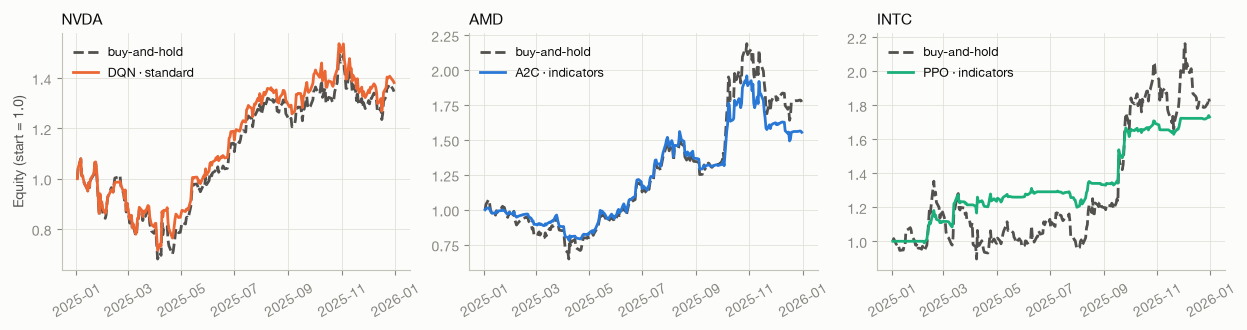

In [7]:
curves = read('''SELECT r.ticker, r.algorithm, r.feature_set, c.date, avg(c.equity) AS equity
                 FROM current_training_runs r JOIN run_equity_curves c ON c.run_id = r.id
                 WHERE c.evaluation_period = 'test' GROUP BY 1, 2, 3, 4''')
baseline_curves = read("SELECT ticker, date, equity FROM buy_and_hold_equity_curves WHERE evaluation_period = 'test'")
fig, axes = plt.subplots(1, len(TICKERS), figsize=(4.2 * len(TICKERS), 3.4), sharey=False)
for ax, ticker in zip(axes, TICKERS):
    best = test[test.ticker == ticker].sort_values("excess_return", ascending=False).iloc[0]
    curve = curves.query("ticker == @ticker and algorithm == @best.algorithm and feature_set == @best.feature_set").sort_values("date")
    bh = baseline_curves.query("ticker == @ticker").sort_values("date")
    ax.plot(bh.date, bh.equity, color=SECONDARY_INK, lw=2, ls="--", label="buy-and-hold")
    ax.plot(curve.date, curve.equity, color=ALGORITHM_COLORS[best.algorithm], lw=2,
            label=f"{best.algorithm} · {best.feature_set}")
    ax.set_title(ticker, loc="left", fontsize=11, color=INK)
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Equity (start = 1.0)")
fig.tight_layout()

## 3. Forward period: performance since training

Trading days after the test window, on agents that were never retrained. Early forward windows are short: treat them as small samples.

In [8]:
forward = (results.query("evaluation_period == 'forward'")
           .merge(comparisons, on=["ticker", "algorithm", "feature_set", "evaluation_period"], suffixes=("", "_cmp")))
if forward.empty:
    print("No forward results yet. Run `make refresh`.")
else:
    print(f"Forward period {forward.period_start.min()} to {forward.period_end.max()}")
    display(pct(forward, ["mean_total_return", "buy_and_hold_return", "excess_return", "excess_return_ci_low",
                          "excess_return_ci_high"])
            [["ticker", "algorithm", "feature_set", "mean_total_return", "buy_and_hold_return", "excess_return",
              "excess_return_ci_low", "excess_return_ci_high", "seeds_beating_buy_and_hold", "beats_buy_and_hold"]]
            .sort_values(["ticker", "excess_return"], ascending=[True, False]).round(2).reset_index(drop=True))

Forward period 2026-01-02 to 2026-11-04


,ticker,algorithm,feature_set,mean_total_return,buy_and_hold_return,excess_return,excess_return_ci_low,excess_return_ci_high,seeds_beating_buy_and_hold,beats_buy_and_hold
0,AMD,DQN,standard,90.63,118.29,-12.67,-40.93,18.12,1,False
1,AMD,A2C,indicators,81.03,118.29,-17.07,-38.22,-0.90,1,False
2,AMD,PPO,standard,79.92,118.29,-17.57,-42.30,2.90,1,False
3,AMD,PPO,indicators,63.32,118.29,-25.18,-55.71,12.61,0,False
4,AMD,A2C,standard,47.29,118.29,-32.52,-65.36,12.78,0,False
5,AMD,DQN,indicators,41.96,118.29,-34.97,-68.93,19.71,0,False
6,INTC,DQN,indicators,53.31,47.67,3.82,-57.06,82.65,3,False
7,INTC,DQN,standard,49.25,47.67,1.07,-35.70,34.64,4,False
8,INTC,A2C,indicators,46.77,47.67,-0.61,-44.72,62.36,3,False
9,INTC,PPO,standard,19.12,47.67,-19.34,-74.89,103.70,1,False


## 4. The answer in one sentence

In [9]:
def verdict(frame, period_name):
    winners = frame[frame.beats_buy_and_hold]
    if winners.empty:
        best = frame.sort_values("excess_return", ascending=False).iloc[0]
        return (f"In the {period_name} period, none of the {len(frame)} strategies beat buy-and-hold with "
                f"{settings.analysis.confidence_level:.0%} confidence; the closest was {best.algorithm} with "
                f"{best.feature_set} features on {best.ticker} ({100 * best.excess_return:+.2f}% vs buy-and-hold).")
    names = ", ".join(f"{r.algorithm}/{r.feature_set} on {r.ticker} ({100 * r.excess_return:+.2f}%)"
                      for r in winners.itertuples())
    return (f"In the {period_name} period, {len(winners)} of {len(frame)} strategies beat buy-and-hold with "
            f"{settings.analysis.confidence_level:.0%} confidence: {names}.")

print(verdict(test, "test"))
if not forward.empty:
    print(verdict(forward, "forward"))

In the test period, none of the 18 strategies beat buy-and-hold with 95% confidence; the closest was DQN with standard features on NVDA (+2.66% vs buy-and-hold).
In the forward period, none of the 18 strategies beat buy-and-hold with 95% confidence; the closest was DQN with indicators features on INTC (+3.82% vs buy-and-hold).
